In [53]:
# Setup

from pathlib import Path

PROJECT_DIR = Path.cwd()
PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

STUDY_AREA = "Nepal, Syabru Besi"
TARGET_CRS = "EPSG:4326"

print(f"Project directory: {PROJECT_DIR}")
print(f"Study area: {STUDY_AREA}")
print(f"Target CRS: {TARGET_CRS}")

Project directory: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project
Study area: Nepal, Syabru Besi
Target CRS: EPSG:4326


In [54]:
#import helper functions does not work currently
import sys
scriptspath = PROJECT_DIR/'scripts'
scriptspath = scriptspath.as_posix()
if scriptspath not in sys.path:
    sys.path.append(scriptspath)
import data_acq_helpers

In [64]:
# define them in the NB for now

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from pyproj import Transformer
from rasterio.windows import from_bounds
from rasterio.windows import transform as window_transform


def bbox_to_dataset_crs(bbox_wgs84, dst_crs):
    """Transform a WGS84 bounding box to a raster's native CRS.

    Rasterio windows must be given in the source file's own CRS, not WGS84.

    Args:
        bbox_wgs84: Bounding box in WGS84 [min_lon, min_lat, max_lon, max_lat].
        dst_crs: Target CRS (e.g., src.crs from rasterio.open()).

    Returns:
        Bounding box in the target CRS [min_x, min_y, max_x, max_y].
    """
    transformer = Transformer.from_crs("EPSG:4326", dst_crs, always_xy=True)
    min_lon, min_lat, max_lon, max_lat = bbox_wgs84
    xs, ys = transformer.transform([min_lon, max_lon], [min_lat, max_lat])
    return min(xs), min(ys), max(xs), max(ys)


def ycbcr_to_rgb(stack):
    """Convert a 3-band YCbCr image (ITU-R BT.601) to RGB uint8.

    Some imagery (e.g. JPEG-compressed GeoTIFFs, as used by SWISSIMAGE) stores
    colour as YCbCr rather than RGB, and must be converted before it can be
    written or plotted as a normal RGB image.

    Args:
        stack: Array of shape (3, height, width) with YCbCr bands.

    Returns:
        RGB array of shape (3, height, width) as uint8.
    """
    y, cb, cr = stack.astype("float32")
    r = y + 1.402 * (cr - 128.0)
    g = y - 0.344136 * (cb - 128.0) - 0.714136 * (cr - 128.0)
    b = y + 1.772 * (cb - 128.0)
    return np.clip(np.stack([r, g, b]), 0, 255).astype("uint8")


def save_single_asset_subset(
    item, asset_key, bbox_wgs84, output_path, band_indexes=(1, 2, 3), conv_ycbcr_to_rgb = True
):
    """Read the AOI window from one raster asset and save it as a GeoTIFF.

    Output pixel dimensions follow the AOI at the source's native resolution,
    so a landscape bbox produces a landscape image (no separate width/height
    arguments needed).

    Args:
        item: A STAC Item object.
        asset_key: String key of the asset to read (e.g., 'B02', 'red', 'image').
        bbox_wgs84: Bounding box in WGS84 [min_lon, min_lat, max_lon, max_lat].
        output_path: File path for the output GeoTIFF.
        band_indexes: Tuple of band indices to read (1-indexed; default (1,2,3) for RGB).

    Returns:
        Path to the written GeoTIFF file.
    """
    href = item.assets[asset_key].href

    with rasterio.open(href) as src:
        print("Source CRS:", src.crs)
        bounds = bbox_to_dataset_crs(bbox_wgs84, src.crs)
        window = from_bounds(*bounds, transform=src.transform)

        stack = src.read(
            list(band_indexes), window=window, boundless=True, fill_value=0
        )
        print("Read shape, dtype:", stack.shape, stack.dtype)

        profile = src.profile.copy()
        profile.update(
            driver="GTiff",
            height=stack.shape[1],
            width=stack.shape[2],
            count=len(band_indexes),
            transform=window_transform(window, src.transform),
            compress="deflate",
        )
        profile.pop("photometric", None)
        
        if (
            str(src.profile.get("photometric", "")).lower() == "ycbcr"
            and stack.shape[0] == 3 and conv_ycbcr_to_rgb == True
        ):
            print("Converting YCbCr -> RGB")
            stack = ycbcr_to_rgb(stack)
        profile.update(dtype=str(stack.dtype))
        

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(stack)

    size_mb = output_path.stat().st_size / 1_000_000
    print(f"Saved: {output_path} ({size_mb:.2f} MB)")
    return output_path


def save_multiband_subset(item, asset_keys, bbox_wgs84, output_path):
    """Read the AOI window from several single-band assets and save as one GeoTIFF.

    Each asset key is read separately (one band each) and stacked in the given
    order, e.g. asset_keys=['B04', 'B03', 'B02'] for a red-green-blue stack.
    Output pixel dimensions follow the AOI at the source's native resolution.

    Args:
        item: A STAC Item object.
        asset_keys: Ordered list of asset keys, one per output band.
        bbox_wgs84: Bounding box in WGS84 [min_lon, min_lat, max_lon, max_lat].
        output_path: File path for the output GeoTIFF.

    Returns:
        Path to the written GeoTIFF file.
    """
    bands = []
    profile = None

    for key in asset_keys:
        with rasterio.open(item.assets[key].href) as src:
            bounds = bbox_to_dataset_crs(bbox_wgs84, src.crs)
            window = from_bounds(*bounds, transform=src.transform)
            band = src.read(1, window=window, boundless=True, fill_value=0)
            bands.append(band)

            if profile is None:
                profile = src.profile.copy()
                profile.update(
                    driver="GTiff",
                    height=band.shape[0],
                    width=band.shape[1],
                    count=len(asset_keys),
                    transform=window_transform(window, src.transform),
                    compress="deflate",
                )
                profile.pop("photometric", None)

    stack = np.stack(bands)
    profile.update(dtype=str(stack.dtype))

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(stack)

    size_mb = output_path.stat().st_size / 1_000_000
    print(f"Saved: {output_path} ({size_mb:.2f} MB)")
    return output_path


def stretch_rgb(rgb):
    """Apply a percentile stretch to an RGB image for better visual contrast.

    Raw satellite data often spans a wide dynamic range. A 2-98 percentile stretch clips
    extreme values and maps the middle 96% to the display range, improving visibility of
    detail without losing important information to saturation.

    Args:
        rgb: Array of shape (3, height, width) or (height, width, 3).

    Returns:
        Stretched array normalized to [0, 1].
    """
    rgb = np.moveaxis(rgb, 0, -1).astype("float32")
    p_low, p_high = np.nanpercentile(rgb, (2, 98))
    if p_high == p_low:
        return np.zeros_like(rgb)
    rgb = (rgb - p_low) / (p_high - p_low)
    return np.clip(rgb, 0, 1)


def plot_rgb(path, title):
    """Load a GeoTIFF and display it as an RGB image with percentile stretch.

    Args:
        path: File path to a 3-band GeoTIFF.
        title: Title for the plot.
    """
    with rasterio.open(path) as src:
        rgb = src.read([1, 2, 3])
    plt.figure(figsize=(7, 3))
    plt.imshow(stretch_rgb(rgb))
    plt.title(title)
    plt.axis("off")
    plt.show()


def inspect_raster(path):
    with rasterio.open(path) as src:
        print("Path:", path)
        print("Width x height:", src.width, "x", src.height)
        print("Bands:", src.count)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Bounds:", src.bounds)
        print("Data type:", src.dtypes[0])
        print("File size:", f"{Path(path).stat().st_size / 1_000_000:.2f} MB")

In [56]:
syabru_coords = [28.164,85.342]

syabru_bbox = [85.32, 28.14 ,85.36, 28.18] # WGS84 lon/lat around Syabru Bensi

from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

search = pc_catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=syabru_bbox,
    datetime="2026-08-01/2026-10-01",
    query={"eo:cloud_cover": {"lt": 20}}, #max cloud cover 20%
    max_items=10,
)

items = list(search.items())
print(f"Found {len(items)} Sentinel-2 item(s)")


Found 3 Sentinel-2 item(s)


In [57]:
for item in items:
    print("Acqusition date: ", item.properties['datetime'])
    print("bbox WGS84: ", item.bbox)
    print("cloud cover: ", item.properties['eo:cloud_cover'])
    print("\n")

Acqusition date:  2026-10-01T04:57:01.025000Z
bbox WGS84:  [84.9485681, 27.9221491, 86.0756583, 28.9251026]
cloud cover:  6.947587


Acqusition date:  2026-09-28T04:47:01.025000Z
bbox WGS84:  [85.2952667, 27.9256583, 86.0831903, 28.9251026]
cloud cover:  1.587821


Acqusition date:  2026-08-12T04:57:01.025000Z
bbox WGS84:  [84.9485681, 27.9221491, 86.0760403, 28.9251026]
cloud cover:  18.746611




Date before:  2026-08-12T04:57:01.025000Z
Date after:  2026-10-01T04:57:01.025000Z
Saved: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\raw\sentinel2\s2_before_syabru_subset.tif (0.77 MB)


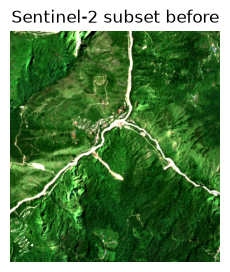

Saved: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\raw\sentinel2\s2_after_syabru_subset.tif (0.78 MB)


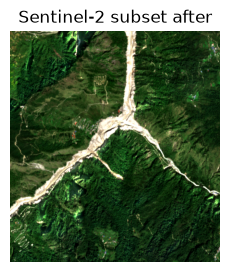

In [ ]:
s2_before = pc.sign(items[2]) #Sign the relevant URLs belonging to any supported object with a Shared Access (SAS) Token, which allows for read access.
s2_after = pc.sign(items[0]) #Sign the relevant URLs belonging to any supported object with a Shared Access (SAS) Token, which allows for read access.

print("Date before: ", s2_before.properties['datetime'])
print("Date after: ", s2_after.properties['datetime'])

#access and plot image before
s2_before_subset = save_multiband_subset(
    item = s2_before,
    bbox_wgs84 = syabru_bbox,
    asset_keys=['B04', 'B03', 'B02'],
    output_path = DATA_DIR / 'raw' / 'sentinel2' / 's2_before_syabru_subset.tif'
)

plot_rgb(s2_before_subset, "Sentinel-2 subset before")

#access and plot image after
s2_after_subset = save_multiband_subset(
    item = s2_after,
    bbox_wgs84 = syabru_bbox,
    asset_keys=['B04', 'B03', 'B02'],
    output_path = DATA_DIR / 'raw' / 'sentinel2' / 's2_after_syabru_subset.tif'
)
plot_rgb(s2_after_subset, "Sentinel-2 subset after")

In [67]:
#inspect the rasters
print("subset before")
inspect_raster(DATA_DIR / 'raw' / 'sentinel2' / 's2_before_syabru_subset.tif')

print("\n")
print("Subset after")
inspect_raster(DATA_DIR / 'raw' / 'sentinel2' / 's2_after_syabru_subset.tif')

subset before
Path: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\raw\sentinel2\s2_before_syabru_subset.tif
Width x height: 399 x 438
Bands: 3
CRS: EPSG:32645
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=335018.91904913314, bottom=3113850.4301308757, right=339008.91904913314, top=3118230.4301308757)
Data type: uint16
File size: 0.77 MB


Subset after
Path: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\data\raw\sentinel2\s2_after_syabru_subset.tif
Width x height: 399 x 438
Bands: 3
CRS: EPSG:32645
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=335018.91904913314, bottom=3113850.4301308757, right=339008.91904913314, top=3118230.4301308757)
Data type: uint16
File size: 0.78 MB


In [ ]:
import leafmap.foliumap as leafmap

m = leafmap.Map(height="300px")
m.add_raster((DATA_DIR / 'raw' / 'sentinel2' / 's2_before_syabru_subset.tif').as_posix(), layer_name="before")


bbox_after_tmp = [84.9485681, 27.9221491, 86.0756583, 28.9251026]
bbox_sw = [bbox_after_tmp[1], bbox_after_tmp[0]]
bbox_ne = [bbox_after_tmp[3], bbox_after_tmp[2]]

#m.fit_bounds([bbox_sw, bbox_ne])
m

In [73]:
import leafmap.foliumap as leafmap

xmin, ymin, xmax, ymax = [84.9485681, 27.9221491, 86.0756583, 28.9251026]

m = leafmap.Map(height="300px")
m.add_raster((DATA_DIR / "raw" / "sentinel2" / "s2_before_syabru_subset.tif").as_posix(), layer_name="before")

geojson = {
    "type": "Feature",
    "properties": {},
    "geometry": {
        "type": "Polygon",
        "coordinates": [[
            [xmin, ymin],
            [xmax, ymin],
            [xmax, ymax],
            [xmin, ymax],
            [xmin, ymin],
        ]]
    },
}

m.add_geojson(geojson, layer_name="bbox")
m


Exception: string indices must be integers, not 'str'